In [ ]:
!pip install ultralytics opencv-python

from google.colab import drive
drive.mount('/content/drive')

import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
import glob
import random

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 9.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Testing on image: /content/drive/MyDrive/face_mask_dataset/test/images/maksssksksss64_png.rf.32c90d9d8f2f042c8c853a24f943ad9b.jpg

image 1/1 /content/drive/MyDrive/face_mask_dataset/test/images/maksssksksss64_png.rf.32c90d9d8f2f042c8c853a24f943ad9b.jpg: 640x640 8 persons, 3 suitcases, 11.0ms
Speed: 92.2ms preprocess, 11.0ms inference, 33.8ms postprocess per image at shape (1, 3, 640, 640)


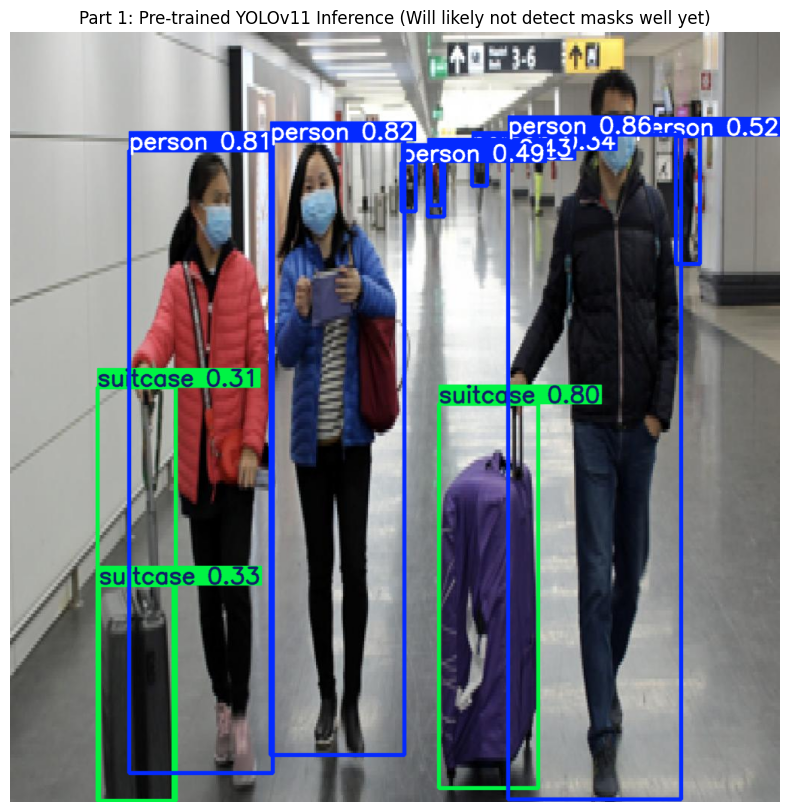

In [ ]:
# --- Part 1: Pre-trained YOLOv11 Inference ---
# Load the pre-trained base model
model_pretrained = YOLO('yolo11n.pt')

test_images = glob.glob('/content/drive/MyDrive/face_mask_dataset/test/images/*.jpg')
test_image_path = random.choice(test_images)
print(f"Testing on image: {test_image_path}")

# Run inference
results = model_pretrained(test_image_path)

# Display the results
res_plotted = results[0].plot()
res_plotted = cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))
plt.imshow(res_plotted)
plt.axis('off')
plt.title('Part 1: Pre-trained YOLOv11 Inference')
plt.show()

In [ ]:
# --- Part 2 & 3: Training YOLOv11 ---
model_custom = YOLO('yolo11n.pt')

print("Starting custom training on the Face Mask dataset...")

results = model_custom.train(
    data='/content/drive/MyDrive/face_mask_dataset/data.yaml',
    epochs=50,
    imgsz=640,
    project='/content/drive/MyDrive/yolo_training',
    name='face_mask_model'
)

print("Training complete! Weights are saved in your Google Drive under 'yolo_training/face_mask_model/weights/'")

Starting custom training on the Face Mask dataset...
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/face_mask_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_sc

Validating model on the test set...
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 2.6±5.0 ms, read: 57.8±42.4 MB/s, size: 102.2 KB)
val: Scanning /content/drive/MyDrive/face_mask_dataset/valid/labels.cache... 170 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 170/170 37.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 1.7it/s 6.3s
                   all        170        668      0.877      0.793      0.866      0.589
 mask_weared_incorrect         23         24      0.816       0.74      0.812      0.566
             with_mask        148        524      0.938      0.897      0.951      0.664
          without_mask         65        120      0.878      0.742      0.836      0.537
Speed: 3.9ms preprocess, 8.2ms inference, 0.0ms loss, 6.1ms postprocess per 

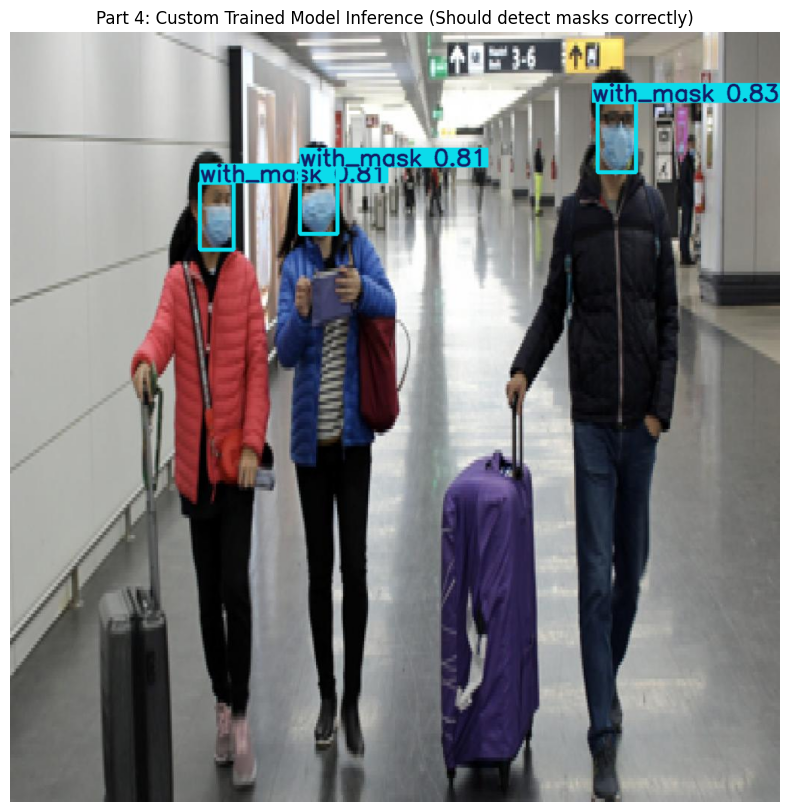

In [ ]:
# --- Part 4: Evaluating and Trained Model ---
print("Validating model on the test set...")
# Validate using the best weights we just trained
metrics = model_custom.val()

print("\nRunning inference with your newly trained Face Mask model...")
# Load best trained weights from the Google Drive save location
best_model_path = '/content/drive/MyDrive/yolo_training/face_mask_model/weights/best.pt'
best_model = YOLO(best_model_path)

# Run inference on the exact same test image used in Part 1 for a direct comparison
custom_results = best_model(test_image_path)

# Display the custom training results
custom_plotted = custom_results[0].plot()
custom_plotted = cv2.cvtColor(custom_plotted, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))
plt.imshow(custom_plotted)
plt.axis('off')
plt.title('Part 4: Custom Trained Model Inference')
plt.show()